# 4 · Robustness across data regimes

Do the conclusions survive the two level shifts in the Bloomberg index quote? This notebook reads `features`, `predictions`
and `spike_predictions` from `data/spx.db`; it fits no forecasting model. It

1. tests whether the June 2011 and December 2016 jumps look like a change in the data definition or a change in liquidity;
2. re-evaluates every main conclusion separately in the three quote eras;
3. adds robust inference: a loss that is not dominated by spike days, block-bootstrap confidence intervals and the
   Model Confidence Set (MCS).

Results are written back as `robust_breaks`, `robust_era_metrics`, `robust_claims` and `robust_mcs`.

In [1]:
import math
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import norm, mannwhitneyu
from sklearn.metrics import roc_auc_score

sns.set_style('darkgrid')
pd.set_option('display.width', 180)
DB_PATH = '../data/spx.db'
SEED    = 42
BLOCK   = 21        # block length (trading days) for all bootstraps
B       = 1000      # bootstrap replications

In [2]:
with sqlite3.connect(DB_PATH) as con:
    df = pd.read_sql('select * from features order by date', con, index_col='date', parse_dates=['date'])
    pred = pd.read_sql('select * from predictions order by rowid', con, parse_dates=['date'])
    spike = pd.read_sql('select * from spike_predictions order by rowid', con, parse_dates=['date'])


def run(experiment, model, spec):
    sub = pred[(pred['experiment'] == experiment) & (pred['model'] == model) & (pred['spec'] == spec)]
    return sub.set_index('date')[['y_true', 'y_pred', 'state', 'block']]


# forecasts compared throughout (all on the same 5,695 days)
models = {
    'Persistence':      run('main', 'Persistence', 'baseline'),
    'Linear':           run('main', 'Linear', 'baseline'),
    'Linear + HAR':     run('har_calendar', 'Linear', '+HAR'),
    'Linear (level y)': run('main', 'Linear (level y)', 'baseline'),
    'XGBoost':          run('main', 'XGBoost', 'baseline'),
    'LightGBM':         run('main', 'LightGBM', 'baseline'),
}
models['Linear, no HMM'] = run('ablation', 'Linear', 'no HMM')
idx = models['Linear'].index
assert all(r.index.equals(idx) for r in models.values())
y = models['Linear']['y_true']
print(f"{len(idx)} forecast days, {idx.min().date()} to {idx.max().date()}")
print({k: int((r['y_pred'] <= 0).sum()) for k, r in models.items() if (r['y_pred'] <= 0).any()}, 'non-positive forecasts (floored for log losses)')

5695 forecast days, 2003-03-28 to 2025-11-13
{'Linear (level y)': 4} non-positive forecasts (floored for log losses)


In [3]:
def diebold_mariano(d):
    # d = loss differential series (A - B); Newey-West variance, HLN correction, t(T-1) p-value.
    # Negative statistic => A has lower loss.
    d = np.asarray(d, float)
    T, dbar = len(d), d.mean()
    lag = int(np.floor(T ** (1 / 3)))
    gamma = lambda k: np.sum((d[:T - k] - dbar) * (d[k:] - dbar)) / T
    S = gamma(0) + 2 * sum((1 - k / (lag + 1)) * gamma(k) for k in range(1, lag + 1))
    dm = dbar / math.sqrt(S / T) * math.sqrt((T - 1) / T)          # HLN factor for h = 1
    return dm, 2 * stats.t.sf(abs(dm), df=T - 1)


def sq_loss(r):          # squared error on the spread level (dominated by spike days)
    return (r['y_true'] - r['y_pred']) ** 2


FLOOR = 1e-5            # the level-target linear model can forecast a negative spread; floor it before taking logs

def log_loss(r):         # absolute log error ~ percentage error (robust to spike days)
    return np.abs(np.log(r['y_true']) - np.log(r['y_pred'].clip(lower=FLOOR)))


def block_boot_idx(n, rng, block=BLOCK, reps=B):
    # moving-block bootstrap: reps x n index matrix
    k = int(np.ceil(n / block))
    starts = rng.integers(0, n - block + 1, size=(reps, k))
    return (starts[:, :, None] + np.arange(block)).reshape(reps, -1)[:, :n]

## 4.1 Are the jumps a change in data definition?

Three checks at each break date:

* **Abruptness.** A methodology change moves the level in a day or two and then stays; a liquidity shock builds up and decays.
* **Other variables.** A real liquidity shock comes with higher volatility and different volume; a definition change does not.
  For every date we compute the standardized shift of a variable between the 60 days before and after it, and report where the
  break-date shift ranks among all dates (percentile of |shift|).
* **Quote structure.** How the bid, ask, mid and last price relate to each other before and after.

In [4]:
ls = df['log_rel_spread']
before_med = ls.shift(1).rolling(21).median()                     # median over [t-21, t-1]
after_med = ls[::-1].rolling(21).median()[::-1]                   # median over [t, t+20]
jump = after_med - before_med

def find_break(start, end):
    w = jump.loc[start:end]
    return w.idxmax(), float(np.exp(w.max()))

breaks = {'2011': find_break('2011-01-01', '2011-12-31'), '2016': find_break('2016-06-01', '2017-06-30')}
for k, (d, m) in breaks.items():
    print(f"{k} break: {d.date()}  (21-day median after / before = x{m:.2f})")

# abruptness: path of log spread normalised so that 0 = old level and 1 = new level
pos = {k: df.index.get_loc(d) for k, (d, _) in breaks.items()}
paths, abrupt = {}, []
for k, p in pos.items():
    old, new = ls.iloc[p - 63:p].median(), ls.iloc[p + 21:p + 84].median()
    z = (ls.iloc[p - 20:p + 41] - old) / (new - old)
    z.index = range(-20, 41)
    paths[k] = z
    settled = z.rolling(5).median()
    hit = settled.loc[0:][settled.loc[0:] >= 0.8]
    days_80 = int(hit.index.min()) if len(hit) else np.nan
    abrupt.append({'break': k, 'date': breaks[k][0].date(), 'multiplier': breaks[k][1],
                   'share of jump on day 0': z.loc[0], 'share on day 1': z.loc[1],
                   'days until 5-day median >= 80%': days_80})
display(pd.DataFrame(abrupt).set_index('break').round(3))

2011 break: 2011-06-01  (21-day median after / before = x6.37)
2016 break: 2016-12-05  (21-day median after / before = x3.72)


,date,multiplier,share of jump on day 0,share on day 1,days until 5-day median >= 80%
break,,,,,
2011,2011-06-01,6.366,0.90,0.801,4
2016,2016-12-05,3.720,1.08,1.114,2


In [5]:
# shifts of other variables around the break dates, ranked against all dates (placebo distribution)
variables = {'log spread': 'log_rel_spread', '|return|': 'abs_return', '5-day volatility': 'rv_5',
             'log volume': 'log_volume', 'return': 'return'}

def std_shift(s, w):
    b_mean, b_sd = s.shift(1).rolling(w).mean(), s.shift(1).rolling(w).std()
    a_mean = s[::-1].rolling(w).mean()[::-1]
    return (a_mean - b_mean) / b_sd

rows = []
for W in [20, 60]:                     # 20 days isolates the break itself; 60 days also covers later market events
    for label, col in variables.items():
        sh = std_shift(df[col], W)
        pool = sh.abs().dropna()
        for k, p in pos.items():
            d = df.index[p]
            before, after = df[col].iloc[p - W:p], df[col].iloc[p:p + W]
            rows.append({'window': W, 'break': k, 'variable': label, 'mean before': before.mean(), 'mean after': after.mean(),
                         'std. shift': sh.loc[d], 'percentile of |shift|': (pool < abs(sh.loc[d])).mean() * 100,
                         'Mann-Whitney p': mannwhitneyu(before, after).pvalue})
shift_tab = pd.DataFrame(rows)
display(shift_tab.pivot_table(index=['break', 'variable'], columns='window', values=['percentile of |shift|', 'Mann-Whitney p'])
        .round(3))

Mann-Whitney p        percentile of |shift|        
window                             20     60                    20      60
break variable                                                            
2011  5-day volatility          0.000  0.000                89.639  95.080
      log spread                0.000  0.000                93.668  98.118
      log volume                0.860  0.077                23.568  73.690
      return                    0.715  0.451                45.781  94.645
      |return|                  0.229  0.007                85.850  96.658
2016  5-day volatility          0.797  0.000                29.582  60.336
      log spread                0.000  0.000                98.673  98.409
      log volume                0.060  0.010                58.604  52.940
      return                    0.968  0.162                39.564  76.507
      |return|                  0.473  0.190                 2.394  54.108

ask above last (%)  last above bid (%)  mid - last (%)  mid vs (bid+ask)/2 (bp)
break window                                                                                 
2011  before              0.0034              0.0331         -0.0124                      0.0
      after               0.1206              0.1098          0.0138                      0.0
2016  before              0.2893              0.3066         -0.0091                      0.0
      after               0.9483              1.2856         -0.1720                      0.0

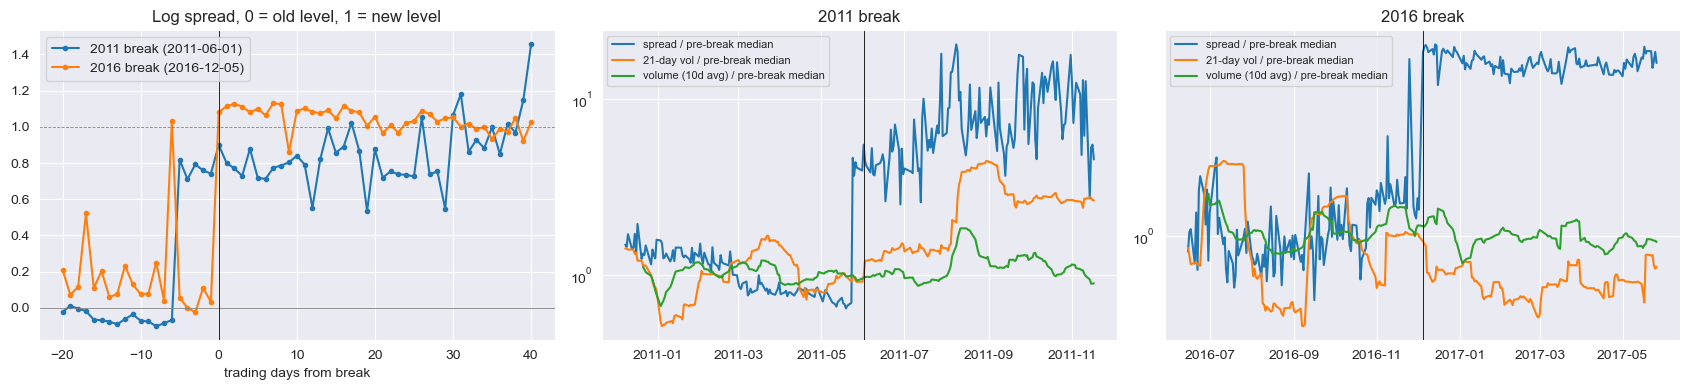

In [6]:
# quote structure before vs after (medians over 60 days)
q = pd.DataFrame({
    'ask above last (%)':  (df['PX_ASK'] - df['PX_LAST']) / df['PX_LAST'] * 100,
    'last above bid (%)':  (df['PX_LAST'] - df['PX_BID']) / df['PX_LAST'] * 100,
    'mid - last (%)':      (df['PX_MID'] - df['PX_LAST']) / df['PX_LAST'] * 100,
    'mid vs (bid+ask)/2 (bp)': (df['PX_MID'] - (df['PX_BID'] + df['PX_ASK']) / 2) / df['PX_MID'] * 1e4,
})
rows = []
for k, p in pos.items():
    for side, sl in [('before', slice(p - 60, p)), ('after', slice(p, p + 60))]:
        rows.append({'break': k, 'window': side, **q.iloc[sl].median().to_dict()})
display(pd.DataFrame(rows).set_index(['break', 'window']).round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for k, z in paths.items():
    axes[0].plot(z.index, z.values, marker='.', label=f"{k} break ({breaks[k][0].date()})")
axes[0].axhline(0, c='gray', lw=0.6); axes[0].axhline(1, c='gray', lw=0.6, ls='--'); axes[0].axvline(0, c='k', lw=0.6)
axes[0].set_xlabel('trading days from break'); axes[0].set_title('Log spread, 0 = old level, 1 = new level'); axes[0].legend()
for ax, (k, p) in zip(axes[1:], pos.items()):
    seg = df.iloc[p - 120:p + 120]
    ax.plot(seg.index, seg['rel_spread'] / seg['rel_spread'].iloc[:120].median(), label='spread / pre-break median')
    ax.plot(seg.index, seg['rv_21'] / seg['rv_21'].iloc[:120].median(), label='21-day vol / pre-break median')
    ax.plot(seg.index, seg['PX_VOLUME'].rolling(10).mean() / seg['PX_VOLUME'].iloc[:120].median(), label='volume (10d avg) / pre-break median')
    ax.axvline(df.index[p], c='k', lw=0.6); ax.set_yscale('log'); ax.set_title(f'{k} break'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

breaks_tab = shift_tab.merge(pd.DataFrame(abrupt)[['break', 'date', 'multiplier']], on='break')

## 4.2 Conclusions by era

Three quote eras split at the detected break dates. The first 21 trading days after each break are left out as a
transition, because every forecast made then still relies on pre-break lags. Losses: squared error on the level (as in
notebook 3) and absolute log error, which measures typical-day accuracy and is not dominated by spike days.

{'A (to May 2011)': 2059, 'B (2011–2016)': 1366, 'C (from Dec 2016)': 2228, 'All days': 5695}


era,A (to May 2011),All days,B (2011–2016),C (from Dec 2016)
"skill vs persistence, absolute log error",,,,
LightGBM,-0.038,-0.040,0.074,-0.093
Linear,0.055,0.048,0.123,0.008
Linear (level y),-0.069,-0.073,0.137,-0.249
Linear + HAR,0.141,0.123,0.192,0.080
"Linear, no HMM",0.044,0.049,0.127,0.014
Persistence,0.000,0.000,0.000,0.000
XGBoost,-0.006,-0.057,0.051,-0.139


era,A (to May 2011),All days,B (2011–2016),C (from Dec 2016)
R² (level),,,,
LightGBM,0.352,0.275,0.156,0.069
Linear,0.490,0.361,0.219,0.178
Linear (level y),0.468,0.336,0.257,0.145
Linear + HAR,0.477,0.360,0.307,0.176
"Linear, no HMM",0.490,0.357,0.216,0.173
Persistence,0.341,0.110,-0.077,-0.147
XGBoost,0.390,0.279,0.135,0.073


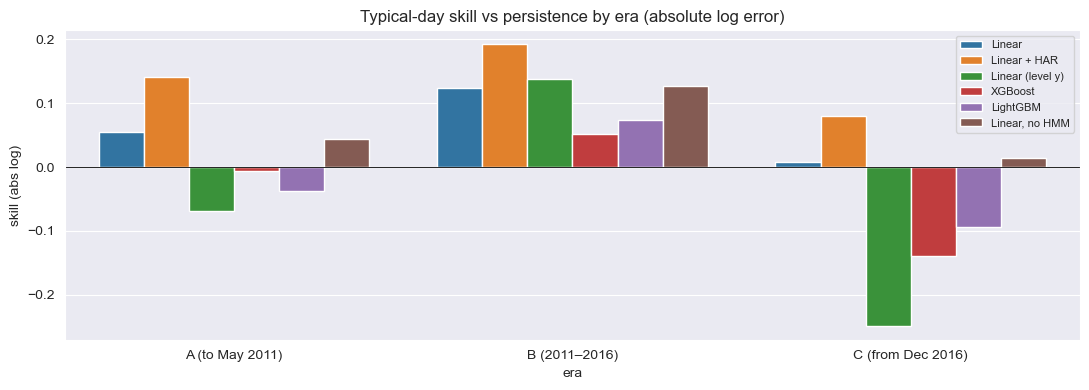

In [7]:
b1, b2 = breaks['2011'][0], breaks['2016'][0]
TRANSITION = 21
after_b1 = idx[idx >= b1][:TRANSITION]
after_b2 = idx[idx >= b2][:TRANSITION]
eras = {
    'A (to May 2011)':    idx[idx < b1],
    'B (2011–2016)':      idx[(idx >= b1) & (idx < b2)].difference(after_b1),
    'C (from Dec 2016)':  idx[idx >= b2].difference(after_b2),
    'All days':           idx,
}
print({k: len(v) for k, v in eras.items()})

rows = []
for era, ix in eras.items():
    bench = models['Persistence'].loc[ix]
    for name, r in models.items():
        r = r.loc[ix]
        mse = sq_loss(r).mean()
        rows.append({'era': era, 'model': name,
                     'R2': 1 - mse / np.var(r['y_true']),
                     'skill (squared, level)': 1 - mse / sq_loss(bench).mean(),
                     'MAE log': log_loss(r).mean(),
                     'skill (abs log)': 1 - log_loss(r).mean() / log_loss(bench).mean()})
era_metrics = pd.DataFrame(rows)
display(era_metrics.pivot(index='model', columns='era', values='skill (abs log)').round(3)
        .rename_axis('skill vs persistence, absolute log error'))
display(era_metrics.pivot(index='model', columns='era', values='R2').round(3).rename_axis('R² (level)'))

plot_data = era_metrics[(era_metrics['era'] != 'All days') & (era_metrics['model'] != 'Persistence')]
plt.figure(figsize=(11, 4))
ax = sns.barplot(data=plot_data, x='era', y='skill (abs log)', hue='model')
ax.axhline(0, c='k', lw=0.6); ax.set_title('Typical-day skill vs persistence by era (absolute log error)')
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

In [8]:
# HMM variants by era (linear model): does any regime design help in any era?
var = {spec: run('hmm_variants', 'Linear', spec) for spec in
       ['no HMM', 'baseline HMM', 'local-z HMM', 'dynamics HMM', 'HMM + interactions']}
rows = []
for era, ix in eras.items():
    ref = var['no HMM'].loc[var['no HMM'].index.intersection(ix)]
    for spec, r in var.items():
        r = r.loc[ref.index]
        p = np.nan if spec == 'no HMM' else diebold_mariano(log_loss(r) - log_loss(ref))[1]
        rows.append({'era': era, 'spec': spec, 'MAE log': log_loss(r).mean(),
                     'Δ MAE log vs no HMM': log_loss(r).mean() - log_loss(ref).mean(), 'DM p (abs log)': p})
display(pd.DataFrame(rows).pivot(index='spec', columns='era', values=['Δ MAE log vs no HMM', 'DM p (abs log)']).round(4))

Δ MAE log vs no HMM                                           DM p (abs log)                                         
era                    A (to May 2011) All days B (2011–2016) C (from Dec 2016) A (to May 2011) All days B (2011–2016) C (from Dec 2016)
spec                                                                                                                                    
HMM + interactions              0.0021   0.0023        0.0004            0.0038          0.4135   0.3460        0.8103            0.4435
baseline HMM                   -0.0017   0.0004        0.0015            0.0013          0.0652   0.5691        0.3166            0.1863
dynamics HMM                   -0.0009   0.0005        0.0023            0.0002          0.0731   0.4048        0.1547            0.7384
local-z HMM                    -0.0002   0.0003        0.0004            0.0001          0.8208   0.4701        0.6410            0.7727
no HMM                          0.0000   0.0000        0.0000            0.0000             NaN      NaN           NaN               NaN

In [9]:
# interval forecasts by era: same construction as notebook 3, section 3.7
r = models['Linear'].copy()
r['e'] = np.log(r['y_true']) - np.log(r['y_pred'])
past_e = r['e'].shift(1)
LB, ALPHA = 250, 0.10
z = norm.ppf(1 - ALPHA / 2)

def sigma_regime(p):
    p_past, e2 = p.shift(1), past_e ** 2
    v_hi = (e2 * p_past).rolling(LB, min_periods=60).sum() / p_past.rolling(LB, min_periods=60).sum()
    v_lo = (e2 * (1 - p_past)).rolling(LB, min_periods=60).sum() / (1 - p_past).rolling(LB, min_periods=60).sum()
    return np.sqrt(p * v_hi + (1 - p) * v_lo)

sig_const = past_e.rolling(LB, min_periods=60).std()
sig_ewma = np.sqrt((past_e ** 2).ewm(alpha=1 - 0.94, min_periods=60).mean())
sig_hmm = sigma_regime(df['prob_state_1_lag1'].reindex(r.index))
sig_local = sigma_regime(df['hmm_local_z_lag1'].reindex(r.index))
sigmas = {'constant': sig_const, 'EWMA': sig_ewma, 'baseline HMM': sig_hmm, 'local-z HMM': sig_local}
y_log, f_log = np.log(r['y_true']), np.log(r['y_pred'])
scores = {}
for name, sig in sigmas.items():
    lo, hi = f_log - z * sig, f_log + z * sig
    scores[name] = (hi - lo) + 2 / ALPHA * (lo - y_log).clip(lower=0) + 2 / ALPHA * (y_log - hi).clip(lower=0)
scores = pd.DataFrame(scores).dropna()

rows = []
for era, ix in eras.items():
    s = scores.loc[scores.index.intersection(ix)]
    rows.append({'era': era, **s.mean().round(4).to_dict(),
                 'p: HMM vs constant': diebold_mariano(s['baseline HMM'] - s['constant'])[1],
                 'p: HMM vs EWMA': diebold_mariano(s['baseline HMM'] - s['EWMA'])[1]})
interval_era = pd.DataFrame(rows).set_index('era')
display(interval_era.round(4))

,constant,EWMA,baseline HMM,local-z HMM,p: HMM vs constant,p: HMM vs EWMA
era,,,,,,
A (to May 2011),0.9463,0.8870,0.9474,0.9195,0.8903,0.0143
B (2011–2016),1.6572,1.6264,1.6564,1.6618,0.9290,0.1103
C (from Dec 2016),1.4698,1.2632,1.4283,1.4839,0.0023,0.0001
All days,1.3661,1.2280,1.3450,1.3611,0.0049,0.0000


In [10]:
# spike classification by era: full logistic model vs the naive distance-to-threshold rule
clf = {spec: g.set_index('date')[['y', 'p']] for spec, g in spike.groupby('spec', sort=False)}
full, base = clf['logit, +HMM+HAR+cal'], clf['logit, no HMM']
naive = full[['y']].assign(p=df.loc[full.index, 'dist_to_thr'])
rng = np.random.default_rng(SEED)

def auc_diff(a, b, ix):
    a, b = a.loc[ix], b.loc[ix]
    est = roc_auc_score(a['y'], a['p']) - roc_auc_score(b['y'], b['p'])
    diffs = []
    for bi in block_boot_idx(len(a), rng, reps=500):
        yy = a['y'].values[bi]
        if yy.min() != yy.max():
            diffs.append(roc_auc_score(yy, a['p'].values[bi]) - roc_auc_score(yy, b['p'].values[bi]))
    return est, *np.percentile(diffs, [2.5, 97.5])

rows = []
for era, ix in eras.items():
    ix = full.index.intersection(ix)
    rows.append({'era': era, 'spike rate': full.loc[ix, 'y'].mean(),
                 'AUC full logit': roc_auc_score(full.loc[ix, 'y'], full.loc[ix, 'p']),
                 'AUC naive rule': roc_auc_score(naive.loc[ix, 'y'], naive.loc[ix, 'p']),
                 **dict(zip(['AUC diff', 'CI low', 'CI high'], auc_diff(full, naive, ix)))})
spike_era = pd.DataFrame(rows).set_index('era')
display(spike_era.round(4))

,spike rate,AUC full logit,AUC naive rule,AUC diff,CI low,CI high
era,,,,,,
A (to May 2011),0.1366,0.8544,0.8197,0.0348,0.0174,0.0712
B (2011–2016),0.1567,0.7845,0.7741,0.0104,-0.0150,0.0394
C (from Dec 2016),0.1436,0.8459,0.8665,-0.0206,-0.0590,0.0163
All days,0.1519,0.8412,0.8330,0.0083,-0.0104,0.0261


## 4.3 Which conclusions hold in every era?

Each claim is tested separately in each era. ✓ = the claim holds at the 5% level (or, for "no gain" claims, no significant
gain in the claimed direction); the number is the effect and the DM p-value on absolute log error unless stated.

In [11]:
def check(holds, text):
    return ('✓ ' if holds else '✗ ') + text

claims = []
for era, ix in eras.items():
    L = {name: log_loss(r.loc[ix]) for name, r in models.items()}
    c = {}
    # 1 the linear model beats boosting on typical days
    d1, p1 = diebold_mariano(L['Linear'] - L['XGBoost'])
    d2, p2 = diebold_mariano(L['Linear'] - L['LightGBM'])
    c['Linear beats XGBoost and LightGBM'] = check(d1 < 0 and d2 < 0 and max(p1, p2) < 0.05,
        f"ΔMAE {L['Linear'].mean() - L['XGBoost'].mean():+.3f} / {L['Linear'].mean() - L['LightGBM'].mean():+.3f}, p {p1:.3f} / {p2:.3f}")
    # 2 HAR improves the linear model
    d, p = diebold_mariano(L['Linear + HAR'] - L['Linear'])
    c['HAR improves the linear model'] = check(d < 0 and p < 0.05, f"ΔMAE {L['Linear + HAR'].mean() - L['Linear'].mean():+.4f}, p {p:.3f}")
    # 3 the best model beats persistence
    d, p = diebold_mariano(L['Linear + HAR'] - L['Persistence'])
    c['Linear + HAR beats persistence'] = check(d < 0 and p < 0.05,
        f"skill {1 - L['Linear + HAR'].mean() / L['Persistence'].mean():+.3f}, p {p:.3f}")
    # 4 the HMM probability adds no significant gain
    d, p = diebold_mariano(L['Linear'] - L['Linear, no HMM'])
    c['HMM adds no point-forecast gain'] = check(not (d < 0 and p < 0.05),
        f"ΔMAE {L['Linear'].mean() - L['Linear, no HMM'].mean():+.4f}, p {p:.3f}")
    # 5 EWMA beats the HMM for intervals (interval score)
    s = scores.loc[scores.index.intersection(ix)]
    d, p = diebold_mariano(s['EWMA'] - s['baseline HMM'])
    c['EWMA beats HMM for intervals'] = check(d < 0 and p < 0.05,
        f"ΔIS {s['EWMA'].mean() - s['baseline HMM'].mean():+.3f}, p {p:.3f}")
    # 6 spike model no better than the naive rule
    row = spike_era.loc[era]
    c['Spike model ≈ naive rule'] = check(row['CI low'] <= 0, f"ΔAUC {row['AUC diff']:+.3f} [{row['CI low']:+.3f}, {row['CI high']:+.3f}]")
    claims.append(pd.Series(c, name=era))
claims = pd.DataFrame(claims).T
with pd.option_context('display.max_colwidth', 60):
    display(claims)

,A (to May 2011),B (2011–2016),C (from Dec 2016),All days
Linear beats XGBoost and LightGBM,"✓ ΔMAE -0.009 / -0.014, p 0.012 / 0.002","✓ ΔMAE -0.025 / -0.017, p 0.006 / 0.019","✓ ΔMAE -0.030 / -0.021, p 0.000 / 0.002","✓ ΔMAE -0.023 / -0.019, p 0.000 / 0.000"
HAR improves the linear model,"✓ ΔMAE -0.0131, p 0.000","✓ ΔMAE -0.0238, p 0.000","✓ ΔMAE -0.0149, p 0.000","✓ ΔMAE -0.0167, p 0.000"
Linear + HAR beats persistence,"✓ skill +0.141, p 0.000","✓ skill +0.192, p 0.000","✓ skill +0.080, p 0.034","✓ skill +0.123, p 0.000"
HMM adds no point-forecast gain,"✓ ΔMAE -0.0017, p 0.054","✓ ΔMAE +0.0013, p 0.362","✓ ΔMAE +0.0013, p 0.187","✓ ΔMAE +0.0003, p 0.617"
EWMA beats HMM for intervals,"✓ ΔIS -0.060, p 0.014","✗ ΔIS -0.030, p 0.110","✓ ΔIS -0.165, p 0.000","✓ ΔIS -0.117, p 0.000"
Spike model ≈ naive rule,"✗ ΔAUC +0.035 [+0.017, +0.071]","✓ ΔAUC +0.010 [-0.015, +0.039]","✓ ΔAUC -0.021 [-0.059, +0.016]","✓ ΔAUC +0.008 [-0.010, +0.026]"


## 4.4 Robust inference on the full sample

* **Block-bootstrap confidence intervals** (21-day moving blocks, 1,000 draws) for the headline effects.
* **Model Confidence Set** (Hansen, Lunde & Nason, 2011; T-max statistic, block bootstrap): the set of models that cannot be
  distinguished from the best at the 10% level, under each loss and in each era. A model's MCS p-value is the level at which it
  would leave the set.

In [12]:
rng = np.random.default_rng(SEED)
BI = block_boot_idx(len(idx), rng)

def ci(series_fn):
    # series_fn(ix) -> scalar statistic on resampled positions
    est = series_fn(np.arange(len(idx)))
    draws = np.array([series_fn(b) for b in BI])
    return est, *np.percentile(draws, [2.5, 97.5])

Lsq = {k: sq_loss(v).values for k, v in models.items()}
Llog = {k: log_loss(v).values for k, v in models.items()}
yv = y.values
r2 = lambda name: (lambda b: 1 - Lsq[name][b].mean() / yv[b].var())
effects = {
    'R² Linear (level)':                       r2('Linear'),
    'R² Linear + HAR (level)':                 r2('Linear + HAR'),
    'R² XGBoost (level)':                      r2('XGBoost'),
    'skill Linear vs persistence (squared)':   lambda b: 1 - Lsq['Linear'][b].mean() / Lsq['Persistence'][b].mean(),
    'skill Linear + HAR vs persistence (abs log)': lambda b: 1 - Llog['Linear + HAR'][b].mean() / Llog['Persistence'][b].mean(),
    'Δ MAE log: HAR − base':                   lambda b: Llog['Linear + HAR'][b].mean() - Llog['Linear'][b].mean(),
    'Δ MAE log: Linear − XGBoost':             lambda b: Llog['Linear'][b].mean() - Llog['XGBoost'][b].mean(),
    'Δ MAE log: with HMM − without':           lambda b: Llog['Linear'][b].mean() - Llog['Linear, no HMM'][b].mean(),
}
ci_tab = pd.DataFrame([(k, *ci(f)) for k, f in effects.items()], columns=['effect', 'estimate', '95% CI low', '95% CI high'])
display(ci_tab.set_index('effect').round(4))

,estimate,95% CI low,95% CI high
effect,,,
R² Linear (level),0.3609,0.2354,0.6308
R² Linear + HAR (level),0.3595,0.2357,0.6615
R² XGBoost (level),0.2789,0.1898,0.5493
skill Linear vs persistence (squared),0.2823,-0.3956,0.4832
skill Linear + HAR vs persistence (abs log),0.1233,0.0823,0.1584
Δ MAE log: HAR − base,-0.0167,-0.0224,-0.0116
Δ MAE log: Linear − XGBoost,-0.0231,-0.0327,-0.0145
Δ MAE log: with HMM − without,0.0003,-0.0010,0.0017


In [13]:
def mcs(losses, names, reps_idx):
    # Model Confidence Set with the T-max statistic; returns MCS p-value per model
    L = np.column_stack([losses[n] for n in names])
    alive, pvals, running = list(range(len(names))), {}, 0.0
    while len(alive) > 1:
        Lm = L[:, alive]
        d = Lm - Lm.mean(axis=1, keepdims=True)                 # d_i. per day
        dbar = d.mean(0)
        boot = np.stack([d[b].mean(0) for b in reps_idx])
        se = np.sqrt(((boot - dbar) ** 2).mean(0))
        t = dbar / se
        p = (((boot - dbar) / se).max(1) >= t.max()).mean()
        worst = alive[int(t.argmax())]
        running = max(running, p)
        pvals[names[worst]] = running
        alive.remove(worst)
    pvals[names[alive[0]]] = 1.0
    return pvals

candidates = ['Persistence', 'Linear', 'Linear + HAR', 'Linear (level y)', 'XGBoost', 'LightGBM']
rows = []
for era, ix in eras.items():
    pos_ix = np.flatnonzero(idx.isin(ix))
    reps_idx = block_boot_idx(len(pos_ix), np.random.default_rng(SEED))
    for loss_name, Ls in [('squared (level)', Lsq), ('abs log', Llog)]:
        p = mcs({k: Ls[k][pos_ix] for k in candidates}, candidates, reps_idx)
        rows.append({'era': era, 'loss': loss_name, **p})
mcs_tab = pd.DataFrame(rows).set_index(['era', 'loss'])
print("MCS p-values (a model is in the 90% Model Confidence Set when its p-value >= 0.10):")
display(mcs_tab.round(3))
print("90% MCS members:")
print(mcs_tab.apply(lambda row: ', '.join(row.index[row >= 0.10]), axis=1).to_string())

MCS p-values (a model is in the 90% Model Confidence Set when its p-value >= 0.10):


Persistence  LightGBM  XGBoost  Linear (level y)  Linear + HAR  Linear
era               loss                                                                                   
A (to May 2011)   squared (level)        0.330     0.330    0.340             0.340         0.655   1.000
                  abs log                0.107     0.107    0.107             0.107         1.000   0.107
B (2011–2016)     squared (level)        0.000     0.003    0.003             0.003         1.000   0.003
                  abs log                0.001     0.005    0.005             0.005         1.000   0.005
C (from Dec 2016) squared (level)        0.550     0.550    0.550             0.550         0.910   1.000
                  abs log                0.273     0.013    0.010             0.010         1.000   0.273
All days          squared (level)        0.530     0.530    0.530             0.530         0.935   1.000
                  abs log                0.008     0.008    0.008             0.008         1.000   0.008

90% MCS members:
era                loss           
A (to May 2011)    squared (level)    Persistence, LightGBM, XGBoost, Linear (level ...
                   abs log            Persistence, LightGBM, XGBoost, Linear (level ...
B (2011–2016)      squared (level)                                         Linear + HAR
                   abs log                                                 Linear + HAR
C (from Dec 2016)  squared (level)    Persistence, LightGBM, XGBoost, Linear (level ...
                   abs log                            Persistence, Linear + HAR, Linear
All days           squared (level)    Persistence, LightGBM, XGBoost, Linear (level ...
                   abs log                                                 Linear + HAR


## 4.5 Write to the database

In [14]:
with sqlite3.connect(DB_PATH) as con:
    breaks_tab.to_sql('robust_breaks', con, if_exists='replace', index=False)
    era_metrics.to_sql('robust_era_metrics', con, if_exists='replace', index=False)
    claims.reset_index(names='claim').to_sql('robust_claims', con, if_exists='replace', index=False)
    mcs_tab.reset_index().to_sql('robust_mcs', con, if_exists='replace', index=False)
    ci_tab.to_sql('robust_effects_ci', con, if_exists='replace', index=False)
print('saved: robust_breaks, robust_era_metrics, robust_claims, robust_mcs, robust_effects_ci')

saved: robust_breaks, robust_era_metrics, robust_claims, robust_mcs, robust_effects_ci
